In [18]:
import csv
import numpy as np
from scipy import stats
from matplotlib import pyplot as plt

In [19]:
with open('Birthweight_reduced_kg_R.csv') as f:
   linecount = sum(1 for line in f)
    
with open('Birthweight_reduced_kg_R.csv',newline='\n') as f:
    reader = csv.reader(f)
    babydata=np.zeros([linecount-1,3],'f')
    counter = 0
    for row in reader:
        if counter != 0:
            babydata[counter-1,0]=row[2]
            babydata[counter-1,1]=row[8]
            babydata[counter-1,2]=row[13]
        counter+=1

PearsonRResult(statistic=np.float32(0.03102252), pvalue=np.float32(0.8453706))
Linear model:  0.0026847003 *x +( 2.8282688 )


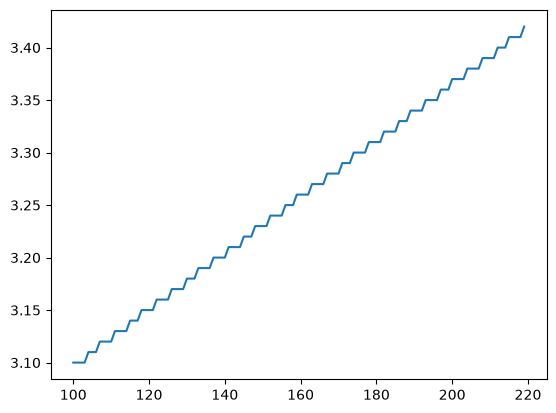

In [20]:
xindep=np.zeros([linecount-1],'f')
xindep=np.array(babydata[:,2]) # changed 1 to 2, which indicates the father's height column
yindep=np.zeros([linecount-1],'f')
yindep=np.array(babydata[:,0])
pcc=stats.pearsonr(xindep,yindep)
print(pcc)
xstddev=np.std(xindep)
ystddev=np.std(yindep)
w=pcc.statistic*ystddev/xstddev
xmean=np.mean(xindep)
ymean=np.mean(yindep)
b=ymean-w*xmean
print("Linear model: ",w,"*x +(",b,")")
x = [i for i in range(100, 220)]
y = [round((w*z+b)*100)/100 for z in x]
plt.plot(x,y)
plt.show()

### Exercise 2
The 2nd independent variable is the father's height - linear model predicts the baby's birth weight based on it.

r = 0.03102252

r is close to 0, which indicates almost no linear correlation.

p = 0.8453706

The correlation is not statistically significant (p = 0.845 > 0.05).